In [16]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return 2 * (x**3) - 9*(x**2) + (12*x) - 4





In [17]:
def golden_section_search_plot(a, b, tol=0.01):
    phi = (1 + np.sqrt(5)) / 2  # golden ratio
    resphi = 2 - phi

    x1 = a + resphi * (b - a)
    x2 = b - resphi * (b - a)
    f1 = f(x1)
    f2 = f(x2)

    intervals = [(a, b)]  # store intervals for plotting
    points = [(x1, f1), (x2, f2)]  # store interior points for plotting

    while abs(b - a) > tol:
        if f1 < f2:
            b = x2
            x2 = x1
            f2 = f1
            x1 = a + resphi * (b - a)
            f1 = f(x1)
        else:
            a = x1
            x1 = x2
            f1 = f2
            x2 = b - resphi * (b - a)
            f2 = f(x2)

        intervals.append((a, b))
        points.append((x1, f1))
        points.append((x2, f2))

    x_min = (a + b) / 2
    f_min = f(x_min)

    return x_min, f_min, intervals, points

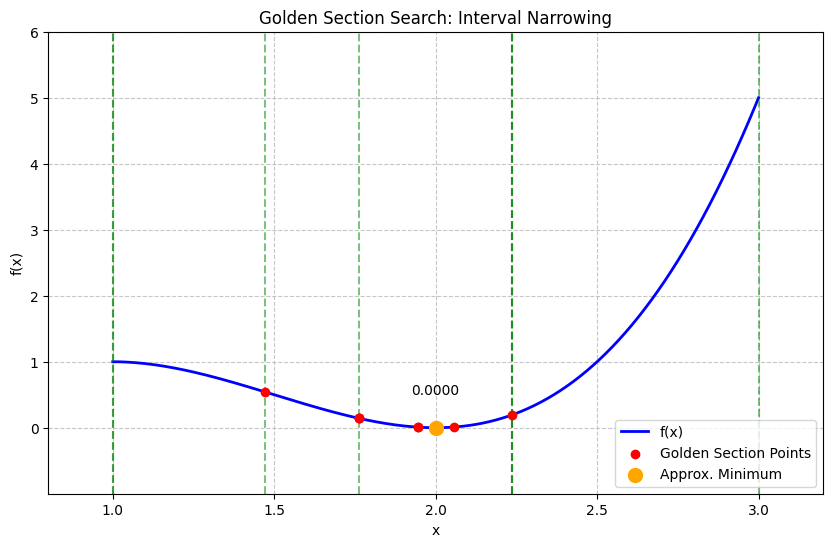

Results for Golden Section Method:
Minimum found at x = 2.0
f(x) = 0.0


In [19]:
# Parameters
a, b = 1,3
tol = 0.5

x_opt, f_opt, intervals, points = golden_section_search_plot(a, b, tol)

# Prepare function curve
x_curve = np.linspace(a, b, 200)
y_curve = f(x_curve)

# Plot function curve
plt.figure(figsize=(10, 6))
plt.plot(x_curve, y_curve, label='f(x)', color='blue', linewidth=2)

# Plot golden section points
points_x = [p[0] for p in points]
points_y = [p[1] for p in points]
plt.scatter(points_x, points_y, color='red', zorder=5, label='Golden Section Points')

# Plot intervals
for (a_i, b_i) in intervals:
    plt.axvline(a_i, color='green', linestyle='--', alpha=0.5)
    plt.axvline(b_i, color='green', linestyle='--', alpha=0.5)

# Highlight final minimum
plt.scatter(x_opt, f_opt, color='orange', s=100, zorder=6, label='Approx. Minimum')
plt.text(x_opt, f_opt + 0.5, f'{f_opt:.4f}', ha='center', fontsize=10)

# Formatting
plt.title('Golden Section Search: Interval Narrowing')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.xlim(a - 0.2, b + 0.2)
plt.ylim(min(y_curve) - 1, max(y_curve) + 1)


plt.savefig('golden_section_plot.png')
plt.show()
print(f"Results for Golden Section Method:")
print(f"Minimum found at x = {x_opt}")
print(f"f(x) = {f_opt}")